# 03 · Combine tracking

File: `combine_tracking.csv` (10 Hz optical tracking, ~6.3k drill attempts).

**Questions:** What drills/attempts exist? Is the tracking clean (frame cadence, gaps, nulls)? Does tracking-derived 40 time agree with the official one?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from utils import *
set_style()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

In [2]:
ct = load_csv("combine_tracking", parse_dates=["time"])
print(ct.shape); ct.head()

(463189, 14)


,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.200,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.785924,28.285528,0.220828,0.682443,0.011085,250.278576
1,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.300,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.723780,28.297391,0.332931,0.619551,0.003864,257.319206
2,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.400,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.632680,28.279528,0.481838,0.596455,0.008305,253.176813
3,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.500,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.544022,28.243767,0.599350,0.664436,0.007964,247.044153
4,2025,20250302100900_1740941802777_000,58286,PLAYER,2025-03-02 18:56:38.600,SKILL_DRILLS_OL,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,4,44.471466,28.210294,0.657540,0.908250,0.005382,240.622668


In [3]:
missingness(ct)

,n_missing,pct_missing,dtype
draft_year,0,0.0,int64
event_id,0,0.0,str
nfl_id,0,0.0,int64
entity_type,0,0.0,str
time,0,0.0,datetime64[us]
drill_type,0,0.0,str
drill_name,0,0.0,str
attempt,0,0.0,int64
x,0,0.0,float64
y,0,0.0,float64


In [4]:
print(ct.entity_type.value_counts())
ev = ct.groupby("event_id").agg(draft_year=("draft_year","first"), drill_type=("drill_type","first"), drill_name=("drill_name","first"),
                                nfl_id=("nfl_id","first"), attempt=("attempt","first"), n=("time","size"), t0=("time","min"), t1=("time","max"))
ev["dur"] = (ev.t1 - ev.t0).dt.total_seconds()
print("events:", len(ev))
ev.head()

entity_type
PLAYER    431094
BALL       32095
Name: count, dtype: int64
events: 6310


,draft_year,drill_type,drill_name,nfl_id,attempt,n,t0,t1,dur
event_id,,,,,,,,,
20240229100000_1709237434916_000,2024,FORTY_YARD_DASH,FORTY_YARD_DASH,57216,1,54,2024-02-29 20:10:34.500,2024-02-29 20:10:39.800,5.3
20240229100000_1709237639326_000,2024,FORTY_YARD_DASH,FORTY_YARD_DASH,57230,1,50,2024-02-29 20:13:59.400,2024-02-29 20:14:04.300,4.9
20240229100000_1709237692456_000,2024,FORTY_YARD_DASH,FORTY_YARD_DASH,57226,1,54,2024-02-29 20:14:54.500,2024-02-29 20:14:59.800,5.3
20240229100000_1709237757151_000,2024,FORTY_YARD_DASH,FORTY_YARD_DASH,57160,1,51,2024-02-29 20:15:55.400,2024-02-29 20:16:00.400,5.0
20240229100000_1709237797792_000,2024,FORTY_YARD_DASH,FORTY_YARD_DASH,57409,1,55,2024-02-29 20:16:35.500,2024-02-29 20:16:40.900,5.4


## Coverage

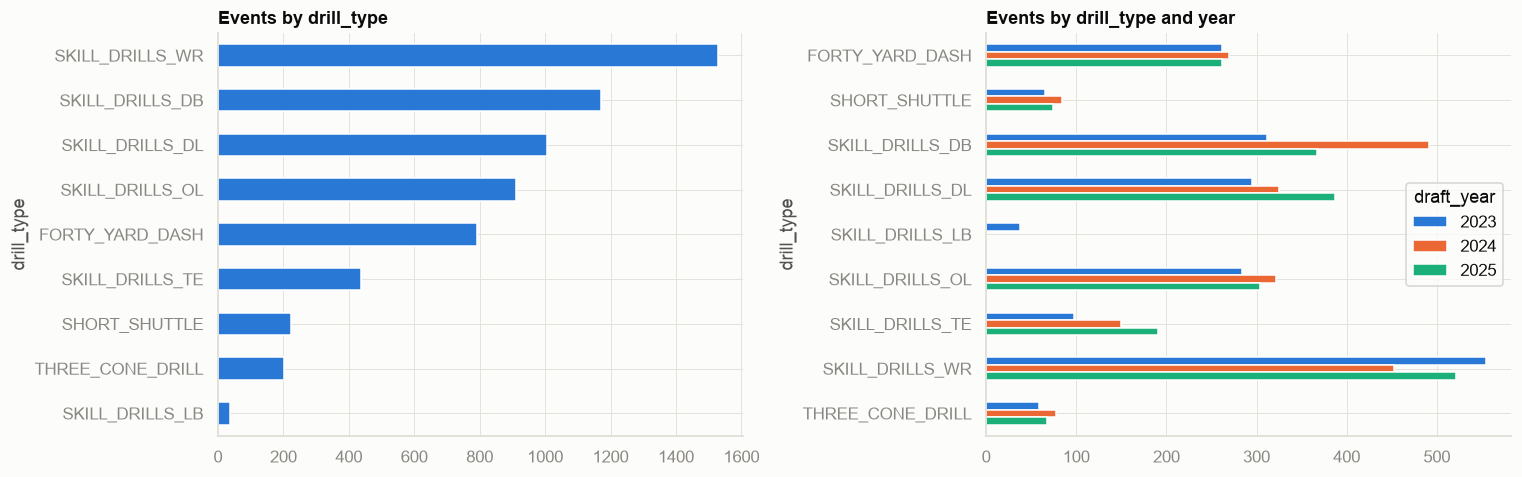

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ev.drill_type.value_counts().plot.barh(color=PALETTE[0], ax=axes[0]); axes[0].set_title("Events by drill_type"); axes[0].invert_yaxis()
ev.groupby(["draft_year","drill_type"]).size().unstack(0).plot.barh(ax=axes[1], color=PALETTE[:3]); axes[1].set_title("Events by drill_type and year"); axes[1].invert_yaxis()
plt.tight_layout(); savefig(fig, "03_coverage")

In [6]:
print(ev.drill_name.value_counts().to_string())
print(); print("players:", ev.nfl_id.nunique(), "| attempts per player per drill:"); ev.groupby(["nfl_id","drill_name"]).size().describe()

drill_name
FORTY_YARD_DASH                                 793
GAUNTLET_DRILL                                  404
BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION    241
PASS_RUSH_DROP                                  239
PASS_RUSH_DRILL                                 225
SHORT_SHUTTLE                                   223
THREE_CONE_DRILL                                203
LINE_DRILL                                      167
OVER_SHOULDER_ADJUST                            135
BOX_DRILL                                       125
W_DRILL                                         124
BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL          124
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE          120
SCREEN_DRILL                                    120
RUN_THE_HOOP_DRILL                              119
SHORT_ZONE_BREAKS                               119
OL_PULL_DRILL_FOLD_BLOCK_RIGHT                  119
DAGGER_ROUTE_LEFT                               115
RUN_AND_CLUB_DRILL                              113
B

count    4986.000000
mean        1.265544
std         0.473664
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         5.000000
dtype: float64

## Tracking quality

gap
0.1    456328
Name: count, dtype: int64


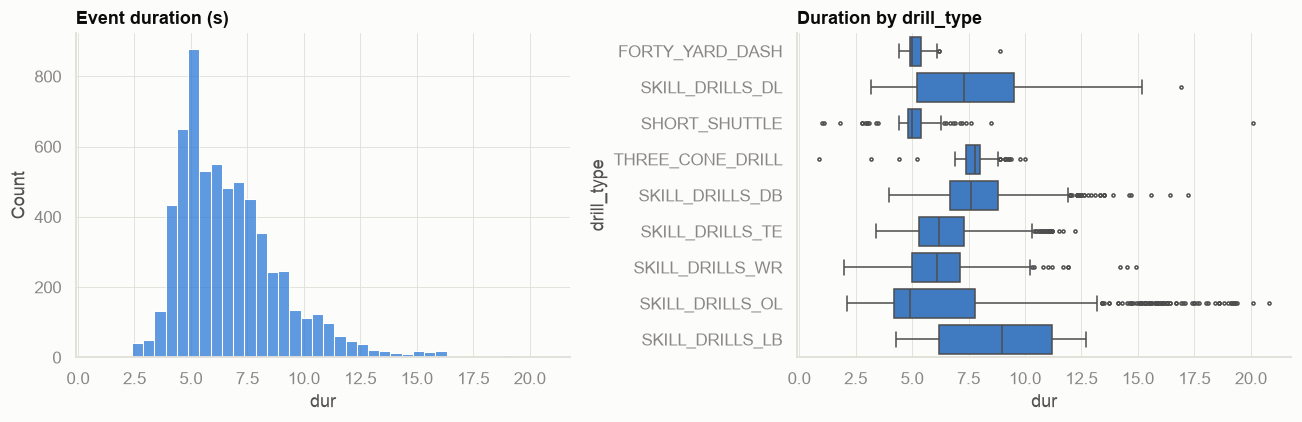

In [7]:
ct = ct.sort_values(["event_id","time"])
ct["gap"] = ct.groupby(["event_id","entity_type"]).time.diff().dt.total_seconds()
print(ct.gap.round(2).value_counts().head(8))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(ev.dur, bins=40, color=PALETTE[0], ax=axes[0]); axes[0].set_title("Event duration (s)")
sns.boxplot(data=ev, y="drill_type", x="dur", color=PALETTE[0], fliersize=2, linewidth=1, ax=axes[1]); axes[1].set_title("Duration by drill_type")
plt.tight_layout()

In [8]:
p = ct[ct.entity_type == "PLAYER"]
print(p[["x","y","s","a","dis"]].describe(percentiles=[.001,.5,.999]).T)
print("out of field bounds:", ((p.x < 0) | (p.x > 120) | (p.y < 0) | (p.y > 53.34)).mean())

        count       mean        std  min       0.1%        50%       99.9%         max
x    431094.0  45.108810  17.239066  1.3  10.189161  44.666667  100.966667  103.900000
y    431094.0  23.954008  14.421745 -7.2  -1.500000  25.900000   55.041774   66.282837
s    431094.0   4.930724   2.843500  0.0   0.033333   4.976667   11.316665   11.854232
a    431094.0   2.831673   1.846506  0.0   0.038006   2.566148    8.544497   10.717722
dis  431094.0   0.299249   0.284143  0.0   0.000000   0.217823    1.284444    1.440000
out of field bounds: 0.11450866864303377


## 40-yard dash

40-yd events: 793


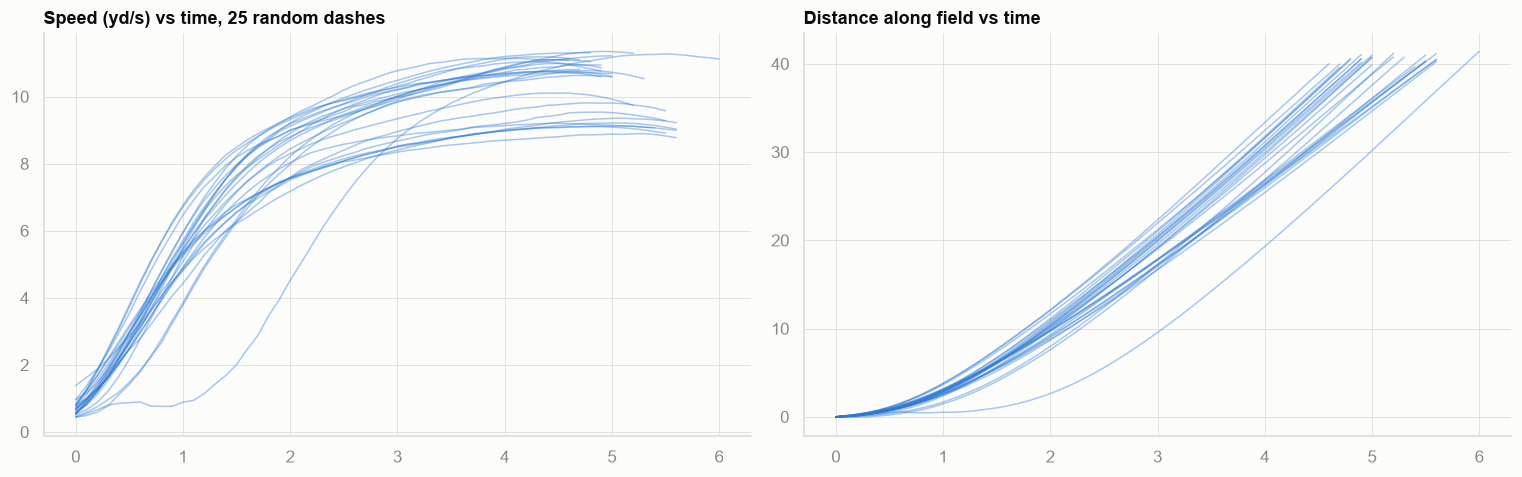

In [9]:
forty = p[p.drill_type == "FORTY_YARD_DASH"].copy()
print("40-yd events:", forty.event_id.nunique())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for eid in forty.event_id.drop_duplicates().sample(25, random_state=0):
    e = forty[forty.event_id == eid]; t = (e.time - e.time.min()).dt.total_seconds()
    axes[0].plot(t, e.s, color=PALETTE[0], alpha=.4, lw=1); axes[1].plot(t, e.x - e.x.iloc[0], color=PALETTE[0], alpha=.4, lw=1)
axes[0].set_title("Speed (yd/s) vs time, 25 random dashes"); axes[1].set_title("Distance along field vs time")
plt.tight_layout(); savefig(fig, "03_forty_curves")

0.7435013217131272 n = 418


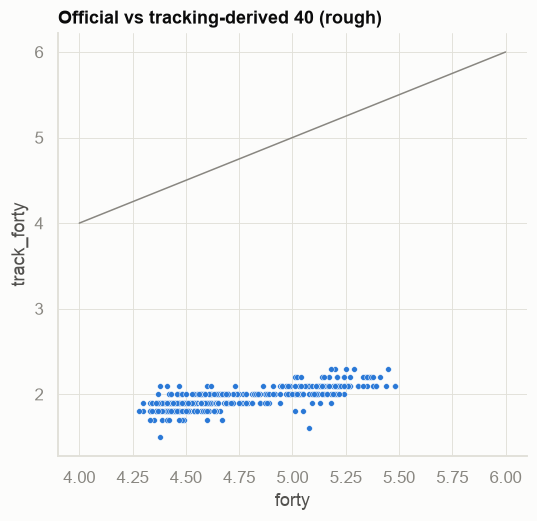

In [10]:
def split_time(e, dist=40/3):
    # time until first frame where displacement along x reaches `dist` yards, from first moving frame
    d = (e.x - e.x.iloc[0]).abs().values; t = (e.time - e.time.iloc[0]).dt.total_seconds().values
    start = t[np.argmax(d > 0.5)] if (d > 0.5).any() else np.nan
    hit = np.argmax(d >= dist) if (d >= dist).any() else None
    return np.nan if hit is None else t[hit] - start
res = forty.groupby(["event_id","nfl_id","draft_year"]).apply(split_time).rename("track_forty").reset_index()
best = res.groupby("nfl_id").track_forty.min().reset_index()
comb = load_csv("combine_results")[["nfl_id","forty"]].merge(best, on="nfl_id")
fig, ax = plt.subplots(figsize=(5.5, 5))
sns.scatterplot(data=comb, x="forty", y="track_forty", s=14, color=PALETTE[0], ax=ax); ax.plot([4, 6], [4, 6], color=MUTED, lw=1); ax.set_title("Official vs tracking-derived 40 (rough)")
print(comb[["forty","track_forty"]].corr().iloc[0,1], "n =", len(comb))

The tracking-derived time here is a crude threshold-crossing estimate (it is not the official timer start/finish), so expect a constant offset; correlation is the useful signal.

## Agility drill paths

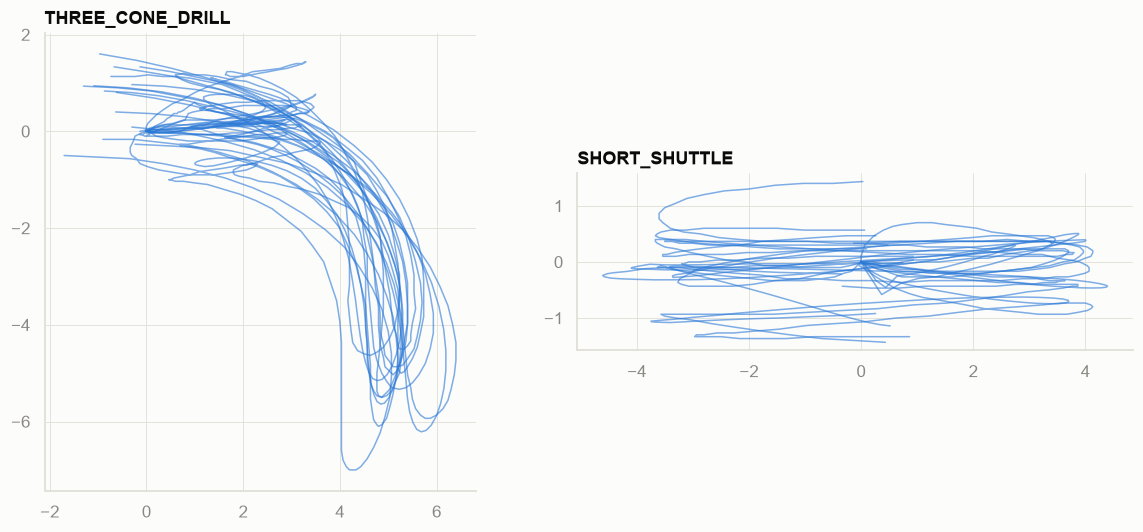

In [11]:
drills = p[p.drill_type.isin(["THREE_CONE_DRILL","SHORT_SHUTTLE"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, dt in zip(axes, ["THREE_CONE_DRILL","SHORT_SHUTTLE"]):
    d = drills[drills.drill_type == dt]
    for eid in d.event_id.drop_duplicates().sample(min(15, d.event_id.nunique()), random_state=0):
        e = d[d.event_id == eid]; ax.plot(e.x - e.x.iloc[0], e.y - e.y.iloc[0], lw=1, alpha=.6, color=PALETTE[0])
    ax.set_title(dt); ax.set_aspect("equal")
plt.tight_layout(); savefig(fig, "03_agility_paths")

## Findings / follow-ups
- Fill in after reviewing outputs.